In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [3]:
# 1. Load dataset
df = pd.read_csv("uber.csv")

print("First five rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

First five rows:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647             

In [4]:
# 2. Preprocess dataset
df = df.dropna()

df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] > 0) &
    (df["passenger_count"] <= 6) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180)) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90))
].copy()

In [5]:
# Convert pickup time into date features
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)
df = df.dropna(subset=["pickup_datetime"])

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

In [7]:
# Calculate distance using Haversine formula
def distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    a = (np.sin((lat2 - lat1) / 2) ** 2 +
         np.cos(lat1) * np.cos(lat2) *
         np.sin((lon2 - lon1) / 2) ** 2)

    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance"] = distance(
    df["pickup_latitude"], df["pickup_longitude"],
    df["dropoff_latitude"], df["dropoff_longitude"]
)

df = df[
    (df["distance"] > 0) &
    (df["distance"] < 200)
].copy()


In [8]:
# 3. Identify outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

outliers = df[
    (df["fare_amount"] < Q1 - 1.5 * IQR) |
    (df["fare_amount"] > Q3 + 1.5 * IQR)
]

print("\nNumber of fare outliers:", len(outliers))



Number of fare outliers: 16546


In [9]:
# Remove fare outliers
df = df[
    (df["fare_amount"] >= Q1 - 1.5 * IQR) &
    (df["fare_amount"] <= Q3 + 1.5 * IQR)
].copy()


Correlation with fare:
pickup_longitude     0.001201
pickup_latitude     -0.002022
dropoff_longitude    0.002039
dropoff_latitude    -0.002238
passenger_count      0.012993
distance             0.596155
hour                -0.013126
day                  0.006566
month                0.026643
fare_amount          1.000000
Name: fare_amount, dtype: float64


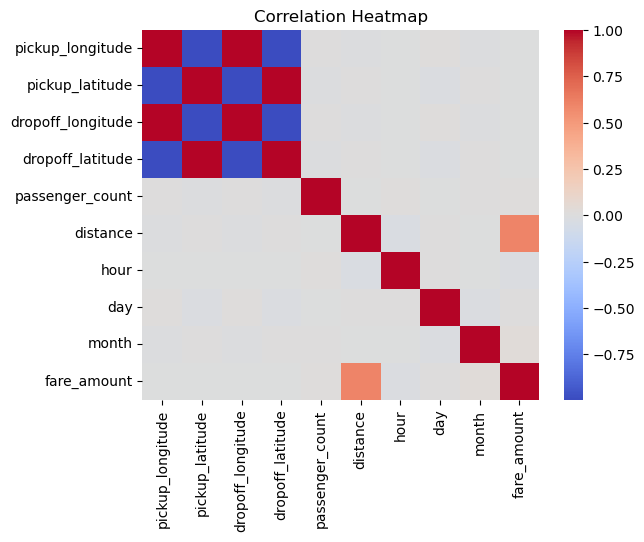

In [10]:
# 4. Check correlation
features = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count", "distance", "hour", "day", "month"
]

print("\nCorrelation with fare:")
print(df[features + ["fare_amount"]].corr()["fare_amount"])

sns.heatmap(
    df[features + ["fare_amount"]].corr(),
    annot=False, cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

In [11]:
# 5. Prepare training and testing data
X = df[features]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred1 = lr.predict(X_test)

# Random Forest Regression
rf = RandomForestRegressor(
    n_estimators=50, random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)
pred2 = rf.predict(X_test)


In [12]:
# 6. Evaluate models
print("\nLinear Regression:")
print("R2 Score:", r2_score(y_test, pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred1)))

print("\nRandom Forest Regression:")
print("R2 Score:", r2_score(y_test, pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))



Linear Regression:
R2 Score: 0.29777946301369684
RMSE: 3.4976447095030956

Random Forest Regression:
R2 Score: 0.7423572704678518
RMSE: 2.118594664674288



Prediction Comparison:
   Actual Fare  Linear Regression  Random Forest
0          9.0           8.396105          8.068
1          6.5           8.610823          8.336
2          8.9           9.930247          8.870
3          5.3           7.570240          6.110
4          6.9           8.689964          8.584


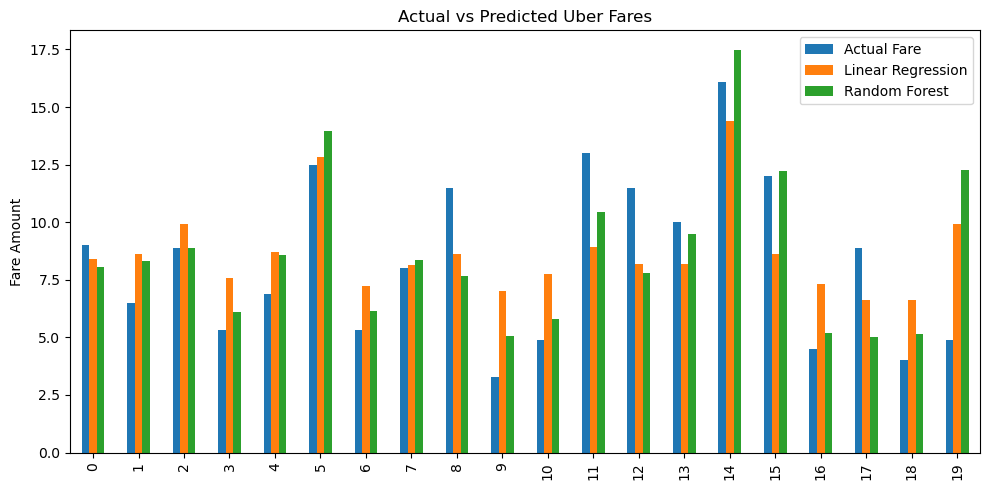

In [13]:
# 7. Compare model performance
results = pd.DataFrame({
    "Actual Fare": y_test.values,
    "Linear Regression": pred1,
    "Random Forest": pred2
})

print("\nPrediction Comparison:")
print(results.head())

results.head(20).plot(kind="bar", figsize=(10, 5))
plt.title("Actual vs Predicted Uber Fares")
plt.ylabel("Fare Amount")
plt.tight_layout()
plt.show()